# Predicting Goodreads Book Bestseller Proxies with Logistic Regression From Scratch
**Client:** Book press  
**Dataset:** `cleaned_goodreads_books_dataset.csv` (supplied dataset)  
**Purpose:** Explore book metadata and build an interpretable binary classifier using a logistic-regression implementation written with NumPy.

> **Important definition:** The dataset does not contain verified bestseller lists or book sales. For this educational study, a *bestseller proxy* is defined as a book with at least **100,000 Goodreads ratings**. This measures platform engagement/popularity, not confirmed commercial sales. Conclusions must be described as predictions of the proxy, not proof of bestseller status.

## 1. Research question and method
Can available book metadata (rating score, pages, publication year, description length, genre count, series status, author follower count, and language indicator) help distinguish books above versus below the 100,000-ratings threshold?

The target-defining variable `ratings` is **excluded from the predictors** to prevent target leakage. The average star rating is a different field (`rating`) and is retained as a possible predictor. All preprocessing is learned from training data only. A stratified train/test split is used, and the final test set is not used to choose hyperparameters.

In [1]:
# Import libraries. NumPy is used to implement logistic regression from scratch.
import ast
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.feature_selection import mutual_info_classif
from IPython.display import display

RANDOM_STATE = 42
DATA_PATH = "cleaned_goodreads_books_dataset.csv"

## 2. Load data and inspect its quality

In [2]:
# Load the supplied CSV. If running elsewhere, place the CSV beside this notebook.
df_raw = pd.read_csv(DATA_PATH)
print("Rows and columns:", df_raw.shape)
display(df_raw.head(5))
display(df_raw.dtypes.to_frame("data_type"))

Rows and columns: (724, 15)


,id,title,series,description,pages,publicationDate,language,rating,ratings,imageURL,genres,amazonLink,ISBN,author,popularReviews
0,49014714,2 Book Collection Set: Conversations with Frie...,NaN,Please Note That The Following Individual Book...,0,2019-01-01,English,3.99,740,https://m.media-amazon.com/images/S/compressed...,['Fiction'],http://www.amazon.com/gp/product/9123926058/re...,9789123926053.0,"{'name': 'Sally Rooney', 'about': 'Sally Roone...","[{'user': {'name': 'Lucy Mckenzie', 'imageURL'..."
1,195854281,3 Book Collection Set: Beautiful World Where A...,NaN,1,0,NaN,English,3.49,35,https://m.media-amazon.com/images/S/compressed...,['Fiction'],https://www.amazon.com/gp/product/B0DJYP1RFC/r...,9780678456934.0,"{'name': 'Sally Rooney', 'about': 'Sally Roone...",[]
2,63063437,4 Book Taylor Jenkins Reid Collection: Malibu ...,NaN,Please Note That The Following Individual Book...,1504,2022-01-01,English,3.89,46,https://m.media-amazon.com/images/S/compressed...,['Fiction'],http://www.amazon.com/gp/product/9123471182/re...,9789123471188.0,"{'name': 'Taylor Jenkins Reid', 'about': 'Tayl...","[{'user': {'name': 'Avani ✨', 'imageURL': 'htt..."
3,39987393,A Book on the Table: Flash Fiction,NaN,This year's story collection includes flash fi...,50,2018-01-01,English,3.75,88,https://m.media-amazon.com/images/S/compressed...,"['Short Stories', 'Fiction', 'Flash Fiction']",http://www.amazon.com/gp/product/099844992X/re...,9780998449920,"{'name': 'Celeste Ng', 'about': ""Celeste Ng is...","[{'user': {'name': 'Drew', 'imageURL': 'https:..."
4,5326,A Christmas Carol,NaN,"'If I had my way, every idiot who goes around ...",184,1999-09-23,English,4.09,914833,https://m.media-amazon.com/images/S/compressed...,"['Classics', 'Fiction', 'Christmas', 'Fantasy'...",https://www.amazon.com/gp/product/B071ZKZBWR/r...,9781561797462,"{'name': 'Charles Dickens', 'about': 'Charles ...",[]


,data_type
id,int64
title,object
series,object
description,object
pages,int64
publicationDate,object
language,object
rating,float64
ratings,int64
imageURL,object


In [3]:
# Summarise missing values, duplicate records, and numeric distributions.
quality = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percent": (df_raw.isna().mean() * 100).round(2),
    "unique_values": df_raw.nunique(dropna=True)
}).sort_values("missing_percent", ascending=False)
display(quality)
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Duplicate IDs:", df_raw["id"].duplicated().sum())
display(df_raw[["rating", "ratings", "pages"]].describe().T)

,missing_count,missing_percent,unique_values
series,417,57.60,302
ISBN,170,23.48,554
publicationDate,19,2.62,571
language,18,2.49,14
description,8,1.10,711
imageURL,7,0.97,717
id,0,0.00,724
pages,0,0.00,358
title,0,0.00,724
ratings,0,0.00,705


Exact duplicate rows: 0
Duplicate IDs: 0


,count,mean,std,min,25%,50%,75%,max
rating,724.0,3.916961,0.358704,0.0,3.72,3.9,4.12,5.0
ratings,724.0,194081.406077,657371.164840,0.0,1413.00,12735.5,113697.50,9799364.0
pages,724.0,364.219613,620.220253,0.0,128.00,320.0,400.00,10358.0


## 3. Clean and engineer features
- Remove duplicate rows and duplicate book IDs (retain the first occurrence).
- Parse publication year safely; invalid/missing dates become missing values.
- Convert genre strings to lists and count genres.
- Parse author follower counts safely from the author metadata.
- Create simple, explainable predictors from fields that would be available as book metadata.
- Fill numeric missing values using the **training-set median**; scale using the training-set mean and standard deviation.
- Do not use `ratings`, `id`, title, ISBN, URLs, images, review text, or the target label as predictors.

In [4]:
# Work on a copy and remove exact duplicates and duplicate IDs.
df = df_raw.drop_duplicates().copy()
df = df.drop_duplicates(subset="id", keep="first").copy()

# Safely extract the year from publicationDate.
df["publication_year"] = pd.to_datetime(df["publicationDate"], errors="coerce").dt.year

# Safely count genres; malformed or missing genre entries return zero.
def count_genres(value):
    if pd.isna(value):
        return 0
    try:
        parsed = ast.literal_eval(value) if isinstance(value, str) else value
        return len(parsed) if isinstance(parsed, (list, tuple, set)) else 0
    except (ValueError, SyntaxError, TypeError):
        return 0

df["genre_count"] = df["genres"].apply(count_genres)

# Safely extract author follower count from the stringified author dictionary.
def get_author_followers(value):
    if pd.isna(value):
        return np.nan
    try:
        parsed = ast.literal_eval(value) if isinstance(value, str) else value
        if isinstance(parsed, dict):
            return pd.to_numeric(parsed.get("followers", np.nan), errors="coerce")
    except (ValueError, SyntaxError, TypeError):
        pass
    return np.nan

df["author_followers"] = df["author"].apply(get_author_followers)

# Feature engineering: log-transform highly skewed non-negative counts.
df["description_length"] = df["description"].fillna("").astype(str).str.len()
df["has_series"] = df["series"].notna().astype(int)
df["is_english"] = df["language"].fillna("").astype(str).str.lower().eq("english").astype(int)
df["log_author_followers"] = np.log1p(df["author_followers"].clip(lower=0))
df["log_pages"] = np.log1p(pd.to_numeric(df["pages"], errors="coerce").clip(lower=0))

# Target: engagement-based bestseller proxy. ratings is not included as an input feature.
THRESHOLD = 100_000
df["bestseller_proxy"] = (pd.to_numeric(df["ratings"], errors="coerce") >= THRESHOLD).astype(int)

feature_cols = [
    "rating", "log_pages", "publication_year", "genre_count",
    "description_length", "has_series", "is_english", "log_author_followers"
]
model_df = df[feature_cols + ["bestseller_proxy"]].copy()
print("Cleaned modelling shape:", model_df.shape)
print("Target counts (0=below threshold, 1=at/above threshold):")
display(model_df["bestseller_proxy"].value_counts().rename_axis("class").to_frame("books"))
print("Target rate:", round(model_df["bestseller_proxy"].mean(), 3))

Cleaned modelling shape: (724, 9)
Target counts (0=below threshold, 1=at/above threshold):


,books
class,
0,530
1,194


Target rate: 0.268


## 4. Exploratory Data Analysis (EDA)

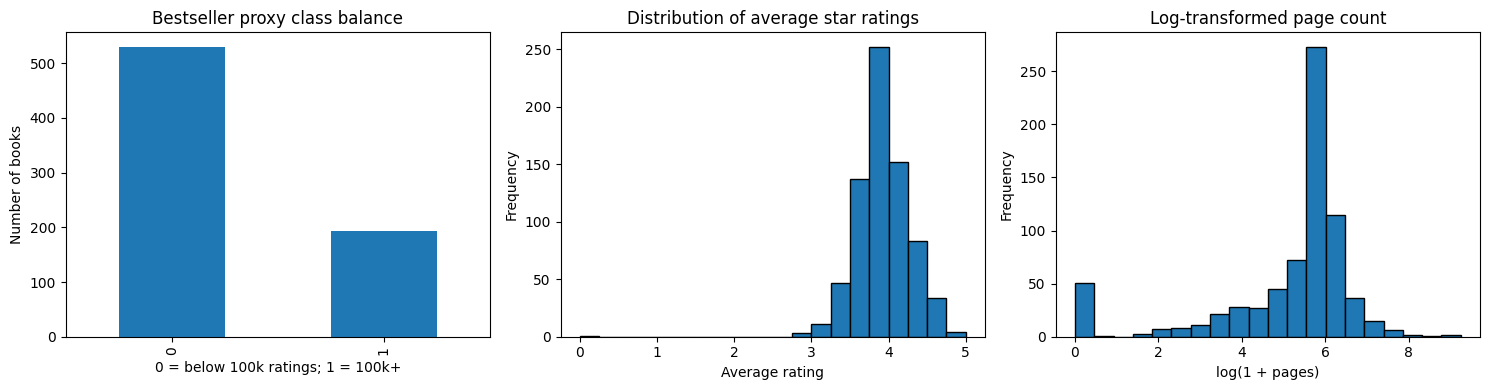

In [5]:
# Plot class balance and numeric distributions to understand the data before training.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
model_df["bestseller_proxy"].value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Bestseller proxy class balance")
axes[0].set_xlabel("0 = below 100k ratings; 1 = 100k+")
axes[0].set_ylabel("Number of books")
model_df["rating"].plot(kind="hist", bins=20, ax=axes[1], edgecolor="black")
axes[1].set_title("Distribution of average star ratings")
axes[1].set_xlabel("Average rating")
model_df["log_pages"].plot(kind="hist", bins=20, ax=axes[2], edgecolor="black")
axes[2].set_title("Log-transformed page count")
axes[2].set_xlabel("log(1 + pages)")
plt.tight_layout()
plt.show()

,Below threshold (0),100k+ ratings (1)
rating,3.90,3.91
log_pages,5.61,5.91
publication_year,2015.00,2018.00
genre_count,10.00,10.00
description_length,799.50,1043.50
has_series,0.00,0.00
is_english,1.00,1.00
log_author_followers,10.26,11.21


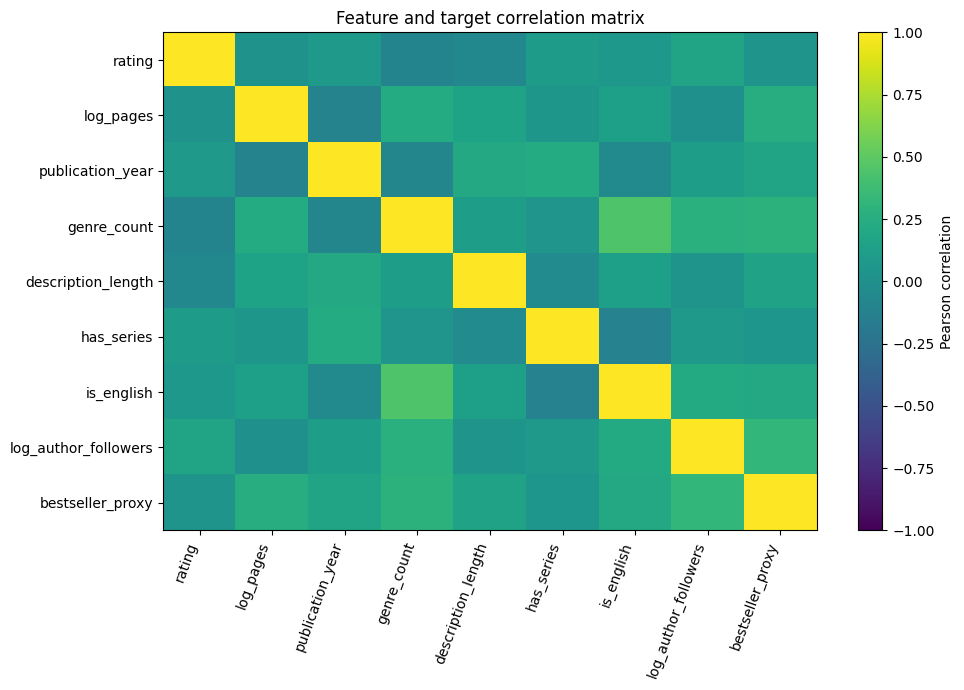

In [6]:
# Compare numerical feature distributions between the two target groups.
eda_summary = model_df.groupby("bestseller_proxy")[feature_cols].median().T
eda_summary.columns = ["Below threshold (0)", "100k+ ratings (1)"]
display(eda_summary.round(2))

# Correlation heatmap helps identify redundant numeric features; correlations are descriptive, not causal.
corr = model_df[feature_cols + ["bestseller_proxy"]].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=70, ha="right")
ax.set_yticks(range(len(corr.index)), corr.index)
ax.set_title("Feature and target correlation matrix")
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

## 5. Feature selection and split
A stratified 70/15/15 split creates training, validation and test sets. Feature selection is informed by mutual information on the training data only. This is a non-parametric relevance screen; it does not establish causation. The ranked scores are inspected and the full small set of defensible metadata features is retained to avoid unstable selection on this modest dataset. The target-defining `ratings` column is never used as a predictor.

In [7]:
X = model_df[feature_cols].replace([np.inf, -np.inf], np.nan)
y = model_df["bestseller_proxy"].astype(int)

# First hold out 15% test data; then split the remaining 85% into train and validation.
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.1764705882,
    random_state=RANDOM_STATE, stratify=y_trainval
)  # approximately 70/15/15 overall

# Learn imputation and scaling values from training data only.
train_medians = X_train.median()
X_train_imp = X_train.fillna(train_medians)
X_val_imp = X_val.fillna(train_medians)
X_test_imp = X_test.fillna(train_medians)

train_means = X_train_imp.mean()
train_stds = X_train_imp.std().replace(0, 1).fillna(1)
X_train_scaled = (X_train_imp - train_means) / train_stds
X_val_scaled = (X_val_imp - train_means) / train_stds
X_test_scaled = (X_test_imp - train_means) / train_stds

mi = mutual_info_classif(X_train_scaled, y_train, random_state=RANDOM_STATE)
mi_scores = pd.Series(mi, index=feature_cols).sort_values(ascending=False)
display(mi_scores.rename("mutual_information_score").to_frame())

,mutual_information_score
log_author_followers,0.135279
log_pages,0.104129
description_length,0.070764
is_english,0.067935
genre_count,0.064982
rating,0.022024
publication_year,0.000000
has_series,0.000000


## 6. Logistic Regression implemented from scratch
For each book, the model calculates a linear score \(z = Xw + b\), then converts it to a probability with the sigmoid function \(p=1/(1+e^{-z})\). The parameters are learned using gradient descent to minimise binary cross-entropy plus an L2 penalty. The implementation uses NumPy rather than scikit-learn's LogisticRegression estimator.

In [8]:
class ScratchLogisticRegression:
    # Binary logistic regression trained with batch gradient descent.
    def __init__(self, learning_rate=0.05, epochs=3000, l2=0.1):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.l2 = l2
        self.weights = None
        self.bias = 0.0
        self.loss_history = []

    @staticmethod
    def sigmoid(z):
        # Clipping prevents overflow in exp for extreme linear scores.
        z = np.clip(z, -35, 35)
        return 1.0 / (1.0 + np.exp(-z))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        for epoch in range(self.epochs):
            probabilities = self.sigmoid(X @ self.weights + self.bias)
            # Binary cross-entropy with a small epsilon for numerical stability.
            eps = 1e-12
            loss = -np.mean(y * np.log(probabilities + eps) +
                            (1-y) * np.log(1-probabilities + eps))
            loss += (self.l2 / (2*n_samples)) * np.sum(self.weights**2)
            self.loss_history.append(loss)

            # Gradients of the loss with respect to weights and bias.
            error = probabilities - y
            dw = (X.T @ error) / n_samples + (self.l2 / n_samples) * self.weights
            db = np.mean(error)
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        p1 = self.sigmoid(X @ self.weights + self.bias)
        return np.column_stack((1-p1, p1))

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

## 7. Train and tune on validation data

In [9]:
# Compare a small, pre-declared set of L2 strengths and learning rates.
# Choose using validation F1, then evaluate the chosen model once on the held-out test set.
candidates = [
    {"learning_rate": 0.01, "epochs": 3000, "l2": 0.01},
    {"learning_rate": 0.03, "epochs": 3000, "l2": 0.1},
    {"learning_rate": 0.05, "epochs": 3000, "l2": 1.0},
]
tuning_rows = []
fitted_candidates = []
for params in candidates:
    candidate = ScratchLogisticRegression(**params)
    candidate.fit(X_train_scaled.to_numpy(), y_train.to_numpy())
    val_probs = candidate.predict_proba(X_val_scaled.to_numpy())[:, 1]
    val_pred = (val_probs >= 0.5).astype(int)
    f1 = f1_score(y_val, val_pred, zero_division=0)
    tuning_rows.append({**params, "validation_f1": f1,
                        "validation_accuracy": accuracy_score(y_val, val_pred),
                        "validation_auc": roc_auc_score(y_val, val_probs)})
    fitted_candidates.append(candidate)

tuning_results = pd.DataFrame(tuning_rows).sort_values("validation_f1", ascending=False)
display(tuning_results)
best_idx = tuning_results.index[0]
best_params = candidates[best_idx]
best_model = fitted_candidates[best_idx]
print("Selected hyperparameters:", best_params)

,learning_rate,epochs,l2,validation_f1,validation_accuracy,validation_auc
1,0.03,3000,0.10,0.489796,0.770642,0.837931
2,0.05,3000,1.00,0.489796,0.770642,0.838793
0,0.01,3000,0.01,0.448980,0.752294,0.825862


Selected hyperparameters: {'learning_rate': 0.03, 'epochs': 3000, 'l2': 0.1}


## 8. Test evaluation and interpretation

,test_score
Accuracy,0.835
Precision,0.789
Recall,0.517
F1 score,0.625
ROC-AUC,0.894


                 precision    recall  f1-score   support

Below threshold       0.84      0.95      0.89        80
  100k+ ratings       0.79      0.52      0.62        29

       accuracy                           0.83       109
      macro avg       0.82      0.73      0.76       109
   weighted avg       0.83      0.83      0.82       109



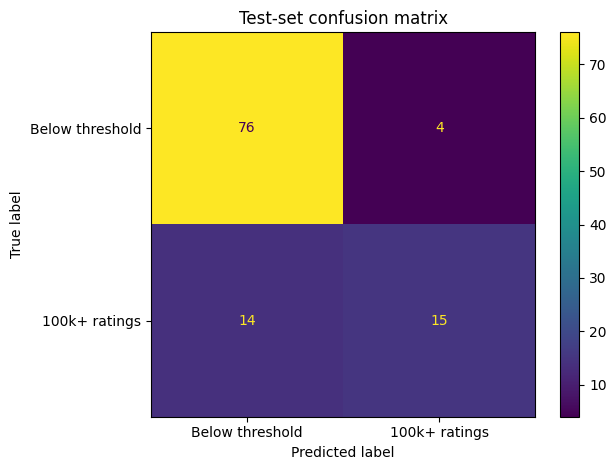

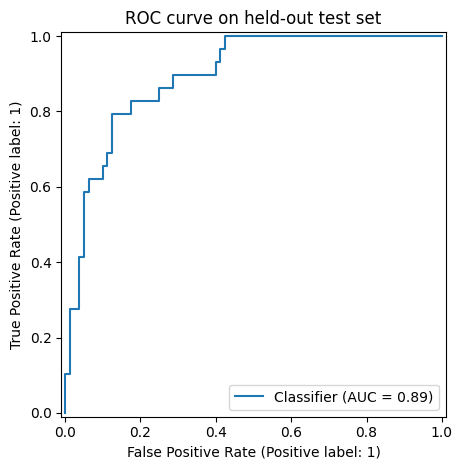

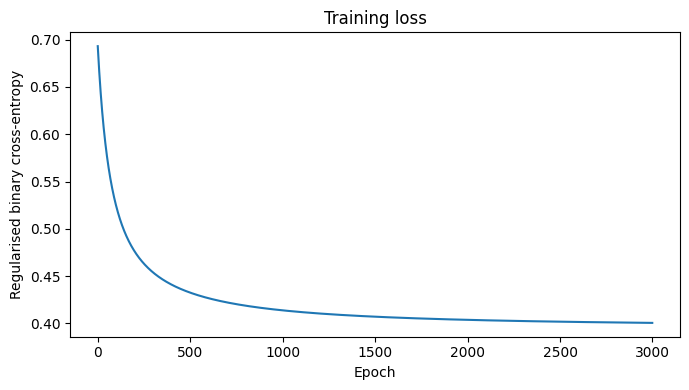

In [10]:
# Test data is used only after selecting hyperparameters from validation performance.
test_prob = best_model.predict_proba(X_test_scaled.to_numpy())[:, 1]
test_pred = (test_prob >= 0.5).astype(int)

metrics = {
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "Recall": recall_score(y_test, test_pred, zero_division=0),
    "F1 score": f1_score(y_test, test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_prob)
}
display(pd.Series(metrics, name="test_score").to_frame().round(3))
print(classification_report(y_test, test_pred, target_names=["Below threshold", "100k+ ratings"], zero_division=0))

# Confusion matrix shows false positives and false negatives.
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["Below threshold", "100k+ ratings"], values_format="d"
)
plt.title("Test-set confusion matrix")
plt.tight_layout()
plt.show()

# ROC curve shows ranking performance across possible probability thresholds.
RocCurveDisplay.from_predictions(y_test, test_prob)
plt.title("ROC curve on held-out test set")
plt.tight_layout()
plt.show()

# Training loss should generally decrease as gradient descent learns.
plt.figure(figsize=(7, 4))
plt.plot(best_model.loss_history)
plt.xlabel("Epoch")
plt.ylabel("Regularised binary cross-entropy")
plt.title("Training loss")
plt.tight_layout()
plt.show()

## 9. Coefficient interpretation and limitations
Because the numeric features were standardised, a positive coefficient means higher values of that feature are associated with higher estimated odds of the 100k-ratings proxy, holding other included features constant. A negative coefficient means the opposite. Coefficients are associations, not causal effects. They should be interpreted alongside uncertainty and the small sample size.

**Limitations:** 724 records is modest for the number of possible book characteristics; missing author followers/publication dates can affect results; Goodreads rating counts depend on platform exposure and book age; the sample may not represent all books; and the proxy is not verified sales data. A production system should be trained on actual historical bestseller outcomes, ideally with time-based validation and sales/distribution features available before publication.

In [11]:
coef_table = pd.DataFrame({
    "feature": feature_cols,
    "standardised_coefficient": best_model.weights
}).sort_values("standardised_coefficient", key=lambda s: s.abs(), ascending=False)
display(coef_table.round(4))

,feature,standardised_coefficient
3,genre_count,1.3196
7,log_author_followers,1.1226
1,log_pages,0.9811
6,is_english,0.7374
2,publication_year,0.4735
4,description_length,0.1280
5,has_series,-0.1181
0,rating,-0.0608
